Full Training Dataset: (120000, 3)
Full Testing Dataset: (7600, 3)
Training Samples Used: 20000
Testing Samples Used: 3000
Training Samples: 18000
Validation Samples: 2000
Testing Samples: 3000

Tokenization Completed
Input IDs and Attention Masks created.


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4453.40it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Training Started...


D:\anaconda3\envs\pytorch_env\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.309381,0.297034,0.917000,0.916851,0.917000,0.916916



MODEL EVALUATION


D:\anaconda3\envs\pytorch_env\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Accuracy : 0.9153
Precision: 0.915
Recall   : 0.9153
F1 Score : 0.9151

Classification Report:
              precision    recall  f1-score   support

       World       0.92      0.91      0.92       759
      Sports       0.97      0.98      0.97       743
    Business       0.88      0.86      0.87       713
  Technology       0.89      0.91      0.90       785

    accuracy                           0.92      3000
   macro avg       0.92      0.91      0.91      3000
weighted avg       0.92      0.92      0.92      3000

Confusion Matrix:
[[691  21  30  17]
 [  5 731   5   2]
 [ 31   2 610  70]
 [ 21   3  47 714]]


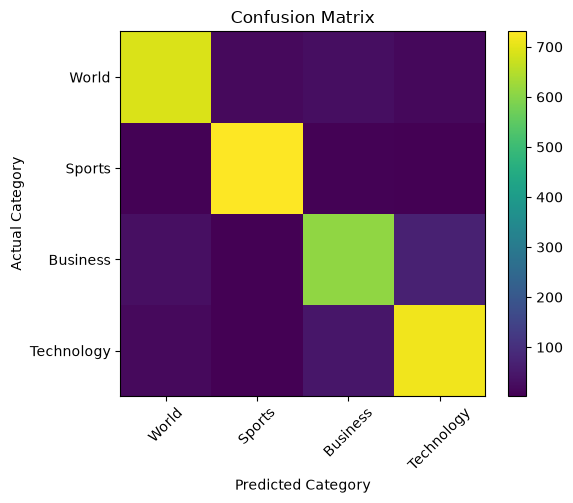


NEW NEWS PREDICTION
News: Apple announces a new smartphone with advanced AI features.
Predicted Category: Technology
Confidence: 98.83 %


In [2]:
# ==========================================================
# SKILL TASK 8 - TRANSFORMER NEWS CLASSIFIER
# ==========================================================

import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

# ----------------------------------------------------------
# 1. Load Dataset
# ----------------------------------------------------------

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Full Training Dataset:", train_df.shape)
print("Full Testing Dataset:", test_df.shape)

# Use smaller dataset for faster training
train_df = train_df.sample(20000, random_state=42)
test_df = test_df.sample(3000, random_state=42)

# Combine Title + Description
train_df["text"] = train_df["Title"] + " " + train_df["Description"]
test_df["text"] = test_df["Title"] + " " + test_df["Description"]

# Class Index: 1,2,3,4 -> 0,1,2,3
train_df["label"] = train_df["Class Index"] - 1
test_df["label"] = test_df["Class Index"] - 1

print("Training Samples Used:", len(train_df))
print("Testing Samples Used:", len(test_df))

# ----------------------------------------------------------
# 2. Train - Validation Split
# ----------------------------------------------------------

train_data, val_data = train_test_split(
    train_df[["text", "label"]],
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_df[["text", "label"]].reset_index(drop=True)

print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_data))

# ----------------------------------------------------------
# 3. Transformer Tokenizer
# ----------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

def tokenize(data):
    return tokenizer(
        data["text"].tolist(),
        padding=True,
        truncation=True,
        max_length=64
    )

train_tokens = tokenize(train_data)
val_tokens = tokenize(val_data)
test_tokens = tokenize(test_data)

print("\nTokenization Completed")
print("Input IDs and Attention Masks created.")

# ----------------------------------------------------------
# 4. PyTorch Dataset
# ----------------------------------------------------------

class NewsDataset(torch.utils.data.Dataset):

    def __init__(self, tokens, labels):
        self.tokens = tokens
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        item = {
            key: torch.tensor(value[index])
            for key, value in self.tokens.items()
        }

        item["labels"] = torch.tensor(
            self.labels[index]
        )

        return item


train_dataset = NewsDataset(
    train_tokens,
    train_data["label"].values
)

val_dataset = NewsDataset(
    val_tokens,
    val_data["label"].values
)

test_dataset = NewsDataset(
    test_tokens,
    test_data["label"].values
)

# ----------------------------------------------------------
# 5. Load Pre-trained Transformer
# ----------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4
)

# ----------------------------------------------------------
# 6. Evaluation Metrics
# ----------------------------------------------------------

def compute_metrics(pred):

    predictions = np.argmax(
        pred.predictions,
        axis=1
    )

    labels = pred.label_ids

    return {
        "accuracy": accuracy_score(
            labels, predictions
        ),
        "precision": precision_score(
            labels,
            predictions,
            average="weighted"
        ),
        "recall": recall_score(
            labels,
            predictions,
            average="weighted"
        ),
        "f1": f1_score(
            labels,
            predictions,
            average="weighted"
        )
    }

# ----------------------------------------------------------
# 7. Train Transformer
# ----------------------------------------------------------

training_args = TrainingArguments(
    output_dir="./news_model",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=100,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("\nTraining Started...")
trainer.train()

# ----------------------------------------------------------
# 8. Test Evaluation
# ----------------------------------------------------------

print("\n==============================")
print("MODEL EVALUATION")
print("==============================")

result = trainer.predict(test_dataset)

predictions = np.argmax(
    result.predictions,
    axis=1
)

actual = test_data["label"].values

print(
    "Accuracy :",
    round(accuracy_score(actual, predictions), 4)
)

print(
    "Precision:",
    round(
        precision_score(
            actual,
            predictions,
            average="weighted"
        ),
        4
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            actual,
            predictions,
            average="weighted"
        ),
        4
    )
)

print(
    "F1 Score :",
    round(
        f1_score(
            actual,
            predictions,
            average="weighted"
        ),
        4
    )
)

# ----------------------------------------------------------
# 9. Classification Report
# ----------------------------------------------------------

categories = [
    "World",
    "Sports",
    "Business",
    "Technology"
]

print("\nClassification Report:")

print(
    classification_report(
        actual,
        predictions,
        target_names=categories
    )
)

# ----------------------------------------------------------
# 10. Confusion Matrix
# ----------------------------------------------------------

cm = confusion_matrix(
    actual,
    predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(
    range(4),
    categories,
    rotation=45
)

plt.yticks(
    range(4),
    categories
)

plt.colorbar()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 11. Predict New News
# ----------------------------------------------------------

news = (
    "Apple announces a new smartphone "
    "with advanced AI features."
)

inputs = tokenizer(
    news,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=64
)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model.to(device)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.no_grad():

    output = model(**inputs)

probabilities = torch.softmax(
    output.logits,
    dim=1
)

prediction = torch.argmax(
    probabilities,
    dim=1
).item()

confidence = (
    probabilities[0][prediction].item()
    * 100
)

print("\n==============================")
print("NEW NEWS PREDICTION")
print("==============================")

print("News:", news)

print(
    "Predicted Category:",
    categories[prediction]
)

print(
    "Confidence:",
    round(confidence, 2),
    "%"
)

In [2]:
%pip install matplotlib -q

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
